# MLflow demo

Generated electricity data only. Compare two models, log their results, and inspect them in MLflow. These are not project evaluation results.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
STORE = ROOT / ".mlflow"
STORE.mkdir(exist_ok=True)
mlflow.set_tracking_uri(f"sqlite:///{STORE / 'mlflow.db'}")
if mlflow.get_experiment_by_name("electricity-demo") is None:
    mlflow.create_experiment("electricity-demo", artifact_location=(STORE / "artifacts").as_uri())
mlflow.set_experiment("electricity-demo")


## 1. Generate data

Two years of daily consumption with a trend, weekly and yearly patterns, and random noise. Train on the earlier days; evaluate on the last 90 days.

In [2]:
rng = np.random.default_rng(42)
dates = pd.date_range("2021-01-01", periods=730, freq="D")
t = np.arange(len(dates))
features = pd.DataFrame({
    "trend": t,
    "weekly_sin": np.sin(2 * np.pi * t / 7),
    "weekly_cos": np.cos(2 * np.pi * t / 7),
    "yearly_sin": np.sin(2 * np.pi * t / 365.25),
    "yearly_cos": np.cos(2 * np.pi * t / 365.25),
}, index=dates)
load = pd.Series(
    1000 + 0.15 * t + 100 * features["weekly_cos"]
    + 180 * features["yearly_cos"] + rng.normal(0, 25, len(t)),
    index=dates, name="consumption_mwh",
)
X_train, X_test = features.iloc[:-90], features.iloc[-90:]
y_train, y_test = load.iloc[:-90], load.iloc[-90:]
print(f"Training days: {len(y_train)}; evaluation days: {len(y_test)}")


Training days: 640; evaluation days: 90


## 2. Train and log two runs

The baseline predicts the training mean. Linear regression uses the calendar patterns and trend. MLflow stores model settings, MAE, RMSE, the fitted model, predictions, and a plot. Lower errors are better.

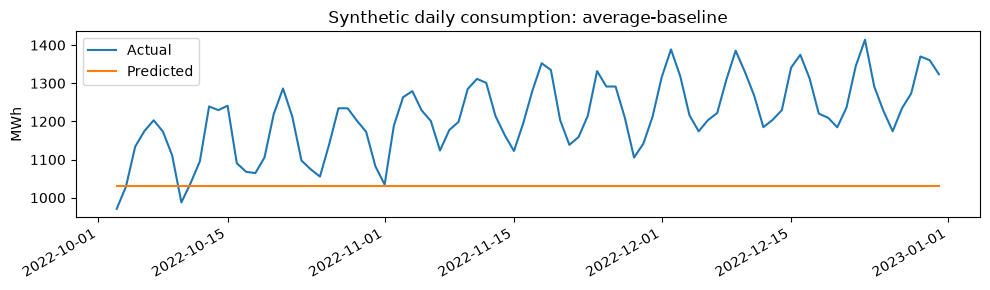

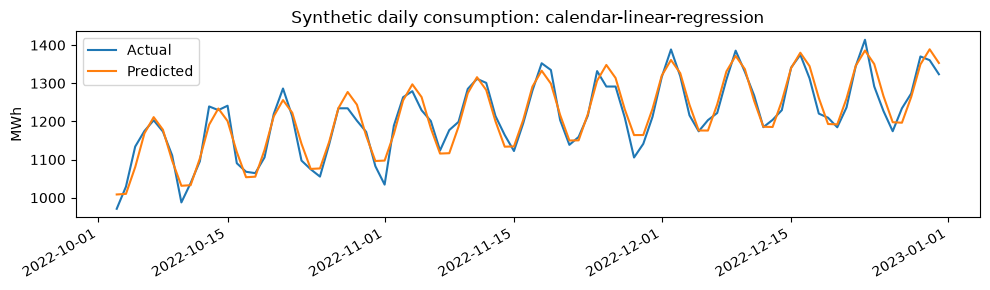

                     model  MAE (MWh)  RMSE (MWh)                           run_id
calendar-linear-regression  21.021019   26.152794 713a659af2054b47b9aee66e82d90d5a
          average-baseline 184.223213  205.756369 55dfa83dfbfc4c43a78157e876f1fbaf


In [3]:
results = []
for name, model in {
    "average-baseline": DummyRegressor(strategy="mean"),
    "calendar-linear-regression": LinearRegression(),
}.items():
    with mlflow.start_run(run_name=name) as run:
        mlflow.set_tag("data_source", "synthetic-demo")
        mlflow.log_params({"model": type(model).__name__, "train_days": len(y_train),
                           "evaluation_days": len(y_test)})
        model.fit(X_train, y_train)
        prediction = model.predict(X_test)
        mae = mean_absolute_error(y_test, prediction)
        rmse = root_mean_squared_error(y_test, prediction)
        mlflow.log_metrics({"mae_mwh": mae, "rmse_mwh": rmse})
        mlflow.sklearn.log_model(model, name="model", input_example=X_train.head(3))
        mlflow.log_table(pd.DataFrame({"date": X_test.index.astype(str),
                                      "actual_mwh": y_test.to_numpy(),
                                      "predicted_mwh": prediction}), "predictions.json")
        fig, ax = plt.subplots(figsize=(10, 3))
        ax.plot(X_test.index, y_test, label="Actual")
        ax.plot(X_test.index, prediction, label="Predicted")
        ax.set(title=f"Synthetic daily consumption: {name}", ylabel="MWh")
        ax.legend()
        fig.autofmt_xdate()
        fig.tight_layout()
        mlflow.log_figure(fig, "actual-vs-predicted.png")
        plt.show()
        plt.close(fig)
        results.append({"model": name, "MAE (MWh)": mae, "RMSE (MWh)": rmse,
                        "run_id": run.info.run_id})

summary = pd.DataFrame(results).sort_values("MAE (MWh)")
print(summary.to_string(index=False))


## 3. View MLflow

From the repository root, run:

```bash
uv run mlflow server --backend-store-uri sqlite:///.mlflow/mlflow.db --host 127.0.0.1 --port 5002
```

Open http://127.0.0.1:5002 and select **electricity-demo**. Select both runs and compare MAE/RMSE. Open a run to inspect its parameters and artifacts. Every notebook execution adds two new runs. The database and artifacts stay in `.mlflow/` on this computer.